## Load python modules

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.special as sp
from scipy.optimize import brentq

plt.rcParams["figure.dpi"] = 100
plt.rc("savefig", dpi=600)
palette_colors = ["#3288bd", "#d53e4f", "#99d594", "#fc8d59"]
pi = math.pi
gamma_fun = sp.gamma
plt.rcParams["font.size"] = 14
plt.rcParams["font.sans-serif"]
plt.rcParams["text.usetex"] = True

# Analytical solution: leak-off toughness-dominated regime

Plane-strain (KGD) fracture driven at a constant rate $Q$ by an inviscid fluid in a
permeable rock, after Bunger, Detournay and Garagash (2005), reproduced as Appendix A3
of Santillán, Juanes and Cueto-Felgueroso (2017).

**Effective parameters (A1) and (A2)**

$$E^\prime=\frac{E}{1-\nu^2},\qquad \mu^\prime=12\mu_f,\qquad
K^\prime=4\sqrt{\tfrac{2}{\pi}}\,K_{Ic},\qquad C^\prime=2C_l,\qquad
K_{Ic}=\sqrt{\frac{g_cE}{1-\nu^2}}=\sqrt{g_cE^\prime}$$

**Scaling (A3)-(A7)**

$$w(x,t)=\epsilon\,L\,\Omega(\xi),\qquad p(x,t)=p_f-\sigma_0=\epsilon\,E^\prime\,\Pi(\xi),\qquad
l(t)=L\,\gamma(\tau),\qquad \xi=\frac{x}{l(t)}$$

with the permeable-medium aspect ratio and length scale (A7) and (A3.1)

$$\epsilon=\frac{C^{\prime 2}}{Q},\qquad L_{k,\tilde k}=\left(\frac{K^\prime Q}{E^\prime C^{\prime 2}}\right)^2$$

**Regime indicators (A3.2) and (A3.3)**

$$\mathcal{M}_{k,\tilde k}=\frac{\mu^\prime Q E^{\prime 3}}{K^{\prime 4}}\ll 1,
\qquad \tau=t\,\frac{E^{\prime 4}C^{\prime 6}}{K^{\prime 4}Q^{2}}$$

$\tau\ll1$ is the storage toughness-dominated regime, $\tau\gg1$ the leak-off
toughness-dominated regime.

**Carter leak-off (A8)**

$$q(x,t)=\frac{C^\prime}{\sqrt{t-t_0(x)}},\qquad t-t_0(x)>0$$

In [2]:
# Material and model parameters
E = 17e9  # Young's modulus (Pa)
nu = 0.2  # Poisson's ratio
Gc0 = 120.0  # Griffith energy (Pa.m)
mu = 1e-8  # fluid dynamic viscosity, fracture and matrix (Pa.s)
Q = 1e-2  # injection rate, both wings (m^2/s)
he = 0.5  # element size of the refined band = ls / diffused_range_parameter (m)
ls = 1.0  # phase-field length scale (m)

L0 = 10.0  # half-length of the pre-existing fracture in the simulation (m)

# In situ state. The closure stress |sigma_v| is NOT applied as a boundary traction:
# the .prj solves the mechanics for the perturbation from the in situ state and passes
# it as <mesocrack_reference_pressure> (p_confining), so the solid and the phase field
# see only the net pressure p_f - p_closure, while the leak-off sees p_f - p_matrix.
# Applied as tractions, the 28 MPa compression (about 30 times the phase-field strength
# sqrt(3 E' Gc / (8 ls)) ~ 0.9 MPa) entered the energy split and made the crack
# propagate at K_I ~ 13 K_Ic.
p_closure = 28e6  # closure stress |sigma_v| = .prj <p_confining> (Pa)

# Effective Griffith energy of the discrete phase-field model
Gc = Gc0 * (3.0 * he / 8.0 / ls + 1.0)
print(f"Gc = {Gc:.4g} Pa m")

Gc = 142.5 Pa m


In [ ]:
# Carter leak-off coefficient of the double-porosity matrix.
#
# The leak-off there is a Darcy exchange with the matrix continuum. Carter's law is
# the large-time limit of that exchange, reached once the matrix pressure diffuses
# like a transient half-space, so the two are related by

#     S_p = porosity * c_f + max(alpha_0 - porosity, 0) * (1 - alpha_0) / K_bulk
#     D_m = K_m / (mu * S_p)                    pressure diffusivity
#     C_l = dp * sqrt(K_m * S_p / (pi * mu))    leak-off velocity into ONE wall

# The second term of S_p is the solid-grain part of the micropore storage. Biot's theory
# requires porosity <= alpha_0 <= 1; below that range HMPhaseField caps the term at zero
# (it would lower the storage and let the matrix pressure drive the crack). With
# alpha_0 = 0 the storage is therefore porosity * c_f.
K_m = 1e-19  # matrix permeability (m^2)        <- .prj <permeability>
phi = 0.3  # porosity                           <- .prj <porosity>
c_f = 4.4e-10  # fluid compressibility (1/Pa)   <- .prj <fluid_compressibility>
alpha_0 = 0.0  # Biot coefficient               <- .prj <biot_coefficient>
# The crack fluid sits at the closure stress plus a small net pressure while the matrix
# far field is held at zero, so the drop across the wall is the closure stress.
dp = p_closure  # pressure drop across the fracture wall (Pa)

K_bulk = E / (3 * (1 - 2 * nu))
S_p = phi * c_f + max(alpha_0 - phi, 0.0) * (1 - alpha_0) / K_bulk
D_m = K_m / (mu * S_p)
C_l = dp * math.sqrt(K_m * S_p / (pi * mu))

print(f"S_p      = {S_p:.4g} 1/Pa")
print(f"D_m      = {D_m:.4g} m^2/s")
print(f"C_l      = {C_l:.4g} m/s^0.5")

S_p      = 1.32e-10 1/Pa
D_m      = 0.07576 m^2/s
C_l      = 0.0005739 m/s^0.5


In [4]:
# Effective parameters (A1), (A2)
K_IC = (E * Gc / (1 - nu**2)) ** 0.5
E_prime = E / (1 - nu**2)
mu_prime = 12 * mu
K_prime = 4 * (2 / pi) ** 0.5 * K_IC
C_prime = 2 * C_l

# Length scale (A3.1), aspect ratio (A7)
L_kkt = (K_prime * Q / (E_prime * C_prime**2)) ** 2
eps = C_prime**2 / Q

# Dimensionless viscosity (A3.2): the solution requires M << 1
M_kkt = mu_prime * Q * E_prime**3 / K_prime**4

# Dimensionless time (A3.3)
tau_of_t = lambda t_i: t_i * E_prime**4 * C_prime**6 / (K_prime**4 * Q**2)

print(f"K_IC    = {K_IC:.4g} Pa m^0.5")
print(f"E'      = {E_prime:.4g} Pa")
print(f"K'      = {K_prime:.4g} Pa m^0.5")
print(f"C'      = {C_prime:.4g} m/s^0.5")
print(f"L_kkt   = {L_kkt:.4g} m")
print(f"eps     = {eps:.4g}")
print(f"M_kkt   = {M_kkt:.4g}  (toughness-dominated if << 1)")

K_IC    = 1.589e+06 Pa m^0.5
E'      = 1.771e+10 Pa
K'      = 5.07e+06 Pa m^0.5
C'      = 0.001148 m/s^0.5
L_kkt   = 4.721 m
eps     = 0.0001318
M_kkt   = 1.009e-05  (toughness-dominated if << 1)


## Dimensionless half-length $\gamma(\tau)$

The integral of Carter's law (A3.9)

$$I_\varphi=\int_0^1\frac{\eta^\varphi}{\sqrt{1-\eta}}\,\mathrm{d}\eta
=\frac{\Gamma(\varphi+1)\Gamma(1/2)}{\Gamma(\varphi+3/2)}$$

**Storage toughness-dominated branch, $\tau\ll1$ (A3.4)-(A3.8)**

$$\gamma_k(\tau)=\tau^{2/3}\sum_{i=0}^{3}\gamma_{ki}\,\tau^{\,i/6}$$

$$\gamma_{k0}=\frac{2}{\pi^{2/3}},\qquad
\gamma_{k1}=-\frac{16I_{2/3}}{3\pi^{4/3}},\qquad
\gamma_{k2}=\frac{32I_{2/3}}{9\pi^{2}}\left(4I_{5/6}-I_{2/3}\right)$$

$$\gamma_{k3}=\frac{512I_{2/3}}{81\pi^{8/3}}
\left[-8I_{5/6}+I_{2/3}\left(2-I_{2/3}+3I_{5/6}\right)\right]$$

**Leak-off toughness-dominated branch, $\tau\gg1$ (A3.10)-(A3.14)**

$$\gamma_{\tilde k}(\tau)=\sqrt{\tau}\sum_{i=0}^{3}\gamma_{\tilde ki}\,\tau^{-i/4}$$

$$\gamma_{\tilde k0}=\frac{1}{\pi},\qquad
\gamma_{\tilde k1}=-\frac{1}{4\sqrt{2\pi}\,I_{1/4}},\qquad
\gamma_{\tilde k2}=\frac{3}{128\,I_{1/4}},\qquad
\gamma_{\tilde k3}=-\frac{3\sqrt{\pi}\left(1+3I_{1/4}\right)}{1024\sqrt{2}\,I_{-1/4}I_{1/4}^{2}}$$

**Three corrections to the printed appendix.**

1. Equation (A3.3) is printed as $\tau=tE^{\prime4}C^{\prime2}/(K^{\prime4}Q^2)$, which
   is not dimensionless. The exponent on $C^\prime$ must be 6. The corrected form
   reproduces the paper's own statement that its case reaches $\tau=1.05$ at
   $t=0.5\,$s; the printed form gives $1.05\times10^{12}$.
2. Equation (A3.4) is printed with the exponent $\tau^{-i/6}$, which makes the
   correction terms grow as $\tau\to0$. It must be $+i/6$.
3. Equations (A3.7) and (A3.8) carry the opposite overall sign to the ones used here.

Corrections 2 and 3 are re-derived from the global volume balance and confirmed below
against its direct numerical solution: the four-term storage series is then accurate to
$0.01\%$ at $\tau=10^{-6}$. The leak-off branch (A3.10)-(A3.14), which is the one this
benchmark needs, is reproduced exactly as printed.

In [5]:
def I_phi(phi_i):
    """Carter integral (A3.9)."""
    return gamma_fun(phi_i + 1.0) * gamma_fun(0.5) / gamma_fun(phi_i + 1.5)


I_23, I_56, I_14, I_m14 = I_phi(2 / 3), I_phi(5 / 6), I_phi(0.25), I_phi(-0.25)

# Storage toughness-dominated coefficients (A3.5)-(A3.8)
gamma_k0 = 2 / pi ** (2 / 3)
gamma_k1 = -16 * I_23 / (3 * pi ** (4 / 3))
gamma_k2 = 32 * I_23 / (9 * pi**2) * (4 * I_56 - I_23)
gamma_k3 = (
    512 * I_23 / (81 * pi ** (8 / 3)) * (-8 * I_56 + I_23 * (2 - I_23 + 3 * I_56))
)

# Leak-off toughness-dominated coefficients (A3.11)-(A3.14)
gamma_kt0 = 1 / pi
gamma_kt1 = -1 / (4 * (2 * pi) ** 0.5 * I_14)
gamma_kt2 = 3 / (128 * I_14)
gamma_kt3 = -3 * pi**0.5 * (1 + 3 * I_14) / (1024 * 2**0.5 * I_m14 * I_14**2)


def gamma_storage(tau, n=3):
    """Dimensionless half-length, storage toughness-dominated branch (A3.4)."""
    c = [gamma_k0, gamma_k1, gamma_k2, gamma_k3]
    tau = np.asarray(tau, dtype=float)
    return tau ** (2 / 3) * sum(c[i] * tau ** (i / 6) for i in range(n + 1))


def gamma_leakoff(tau, n=3):
    """Dimensionless half-length, leak-off toughness-dominated branch (A3.10)."""
    c = [gamma_kt0, gamma_kt1, gamma_kt2, gamma_kt3]
    tau = np.asarray(tau, dtype=float)
    return np.sqrt(tau) * sum(c[i] * tau ** (-i / 4) for i in range(n + 1))


print("gamma_k  =", gamma_k0, gamma_k1, gamma_k2, gamma_k3)
print("gamma_kt =", gamma_kt0, gamma_kt1, gamma_kt2, gamma_kt3)

gamma_k  = 0.9323881540708233 -1.7135982224512083 2.1957766302884827 -1.863078309910253
gamma_kt = 0.3183098861837907 -0.05705570989685079 0.01340788646780531 -0.0031312126775208285


## Verification: global volume balance

For an inviscid fluid the net pressure is uniform, so Sneddon's profile and
$K_I=p\sqrt{\pi l}=K_{Ic}$ give $p=K^\prime/(4\sqrt{2l})$ and
$w=\left(K^\prime/\sqrt{2}E^\prime\right)\sqrt{l}\,\sqrt{1-\xi^2}$. Injected volume
equals the volume stored in the fracture plus the volume lost to the matrix,

$$Qt=\frac{\pi K^\prime}{2\sqrt{2}E^\prime}l^{3/2}
+2C^\prime\int_0^t\frac{l(s)}{\sqrt{t-s}}\,\mathrm{d}s,$$

which in the scaling above is the single equation

$$\tau=\frac{\pi}{2\sqrt{2}}\,\gamma^{3/2}
+2\int_0^\tau\frac{\gamma(\sigma)}{\sqrt{\tau-\sigma}}\,\mathrm{d}\sigma .$$

It is solved below by product integration. It is exact for any $\tau$, so it both
checks the two series and covers the transition between them.

In [6]:
def gamma_volume_balance(tau_end, N=4000):
    """Solve tau = (pi/2sqrt2) g^1.5 + 2 int_0^tau g(s)(tau-s)^-0.5 ds on [0, tau_end].

    Piecewise-linear gamma with exact integration of the Abel kernel; returns the
    nodes and the corresponding gamma.
    """
    d = tau_end / N
    g = np.zeros(N + 1)
    m = np.arange(1, N + 1)
    A = 2 * np.sqrt(d) * (np.sqrt(m) - np.sqrt(m - 1))
    B = (2 / 3) * d**1.5 * (m**1.5 - (m - 1) ** 1.5)
    wL = A - m * A + B / d  # weight on gamma_j,     m = n - j
    wR = m * A - B / d  # weight on gamma_{j+1}
    self_w = wR[0]
    Ks = pi / (2 * 2**0.5)
    for n in range(1, N + 1):
        mm = n - np.arange(0, n)
        hist = np.dot(wL[mm - 1], g[0:n]) + np.dot(wR[mm - 1][:-1], g[1:n])
        rhs = n * d
        f = lambda x: Ks * x**1.5 + 2 * (hist + self_w * x) - rhs
        hi = max((rhs / Ks) ** (2 / 3), rhs / (2 * self_w)) * 1.5 + 1e-30
        g[n] = brentq(f, 0.0, hi, xtol=1e-16, rtol=8.9e-16)
    return np.linspace(0.0, tau_end, N + 1), g

In [7]:
# Accuracy of the two series against the volume balance
print("  tau        exact        storage series      leak-off series")
for te in [1e-6, 1e-4, 1e-2, 0.1, 1.0, 10.0, 100.0, 1000.0]:
    _, gv = gamma_volume_balance(te, 4000)
    ex = gv[-1]
    es = (gamma_storage(te) - ex) / ex * 100
    el = (gamma_leakoff(te) - ex) / ex * 100
    print(f"{te:9.0e}  {ex:.6e}   {es:+10.4f} %      {el:+10.4f} %")

  tau        exact        storage series      leak-off series
    1e-06  7.811981e-05      -0.0096 %      -111589.9037 %
    1e-04  1.396452e-03      -0.2596 %      -1562.7577 %
    1e-02  2.138451e-02      -8.0204 %        -19.1260 %
    1e-01  7.796662e-02     -46.1273 %         -1.9922 %
    1e+00  2.720806e-01    -264.8452 %         -0.2020 %
    1e+01  9.169558e-01   -1488.8706 %         -0.0202 %
    1e+02  3.015151e+00   -8101.6174 %         -0.0020 %
    1e+03  9.757865e+00   -42572.8429 %         -0.0002 %


## Fracture half-length, aperture and net pressure

With (A3.15), (A3.16) the dimensionless opening and pressure are

$$\Omega_{k,\tilde k}=2^{-1/2}\gamma^{1/2}\sqrt{1-\xi^2},
\qquad \Pi_{k,\tilde k}=2^{-5/2}\gamma^{-1/2},$$

so that, back in physical variables,

$$l(t)=L_{k,\tilde k}\,\gamma(\tau),\qquad
w(x,t)=\frac{K^\prime}{\sqrt{2}E^\prime}\sqrt{l(t)}\,\sqrt{1-\xi^2},\qquad
p(x,t)=\frac{K^\prime}{4\sqrt{2\,l(t)}} .$$

The net pressure is uniform along the fracture, and in the leak-off limit
$\gamma\to\sqrt{\tau}/\pi$ the half-length reduces to $l=Q\sqrt{t}/(\pi C^\prime)$.

### Onset offset

The analytical fracture starts from zero length at $t=0$, while the simulation starts
from a pre-existing half-length $L_0$. The two are therefore compared with an offset:
simulated time $t_{\mathrm{sim}}$ is matched against analytical time
$t_{\mathrm{sim}}+t_0$, where $l(t_0)=L_0$. Santillán and coauthors do the same, noting
that their 2.2 m initial fracture is reached analytically at 0.65 s.

One caveat this introduces. Carter's law carries memory of when each point of the wall
was first exposed, so the analytical state at $t_0$ presumes the matrix pressure field
left behind by growth over $[0,t_0]$. A simulation started cold has no such history, and
the first few seconds will show a transient rather than a permanent offset.

A second reference removes that ambiguity. The section *Same-start reference* below
solves the same equations from the simulation's own initial state: the half-length
starts at $L_0$ with zero net pressure, and its walls start leaking at $t=0$. It is the
fairer target for the simulation.

In [8]:
# Branch used for the comparison: "leakoff" (tau >> 1), "storage" (tau << 1)
# or "exact" (volume balance, valid everywhere).
BRANCH = "leakoff"


def l_t(gamma_i):
    """Fracture half-length (A5)."""
    return L_kkt * gamma_i


def w_x_t(xi_i, gamma_i):
    """Fracture aperture (A3), (A3.15)."""
    return (
        eps * L_kkt * 2**-0.5 * np.sqrt(gamma_i) * np.sqrt(1.0 - np.asarray(xi_i) ** 2)
    )


def p_x_t(xi_i, gamma_i):
    """Net pressure p_f - sigma_0 (A4), (A3.16); uniform along the fracture."""
    return (
        eps
        * E_prime
        * 2**-2.5
        / np.sqrt(gamma_i)
        * np.ones_like(np.asarray(xi_i, dtype=float))
    )


# Leading-order estimate l = Q sqrt(t) / (pi C'), used to bracket the onset time
t0_guess = (L0 * pi * C_prime / Q) ** 2

if BRANCH == "exact":
    _tau_tab, _g_tab = gamma_volume_balance(tau_of_t(10 * t0_guess + t_end), 20000)


def gamma_of_tau(tau):
    tau = np.asarray(tau, dtype=float)
    if BRANCH == "leakoff":
        return gamma_leakoff(tau)
    if BRANCH == "storage":
        return gamma_storage(tau)
    if BRANCH == "exact":
        return np.interp(tau, _tau_tab, _g_tab)
    raise ValueError(BRANCH)

In [10]:
# Onset time: when the analytical half-length reaches the pre-existing fracture L0
t0 = brentq(
    lambda ti: float(l_t(gamma_of_tau(tau_of_t(ti)))) - L0,
    t0_guess * 1e-3,
    t0_guess * 1e3,
)
t_end = 200.0  # duration of the simulation (s)
print(f"t0 = {t0:.3f} s   (analytical half-length reaches L0 = {L0:.1f} m)")
print(f"comparison window: analytical t in [{t0:.2f}, {t0 + t_end:.2f}] s")
print(f"tau over the window: {tau_of_t(t0):.4g} -> {tau_of_t(t0 + t_end):.4g}")
print(
    f"half-length over the window: {L0:.2f} -> "
    f"{float(l_t(gamma_of_tau(tau_of_t(t0 + t_end)))):.2f} m"
)

# Carter validity. The diffusion length has to be resolved by the mesh, to exceed the
# band-exchange length, and to stay small compared with the fracture half-length.
he_band = ls / 2.0  # he = ls / diffused_range_parameter in HMPhaseFieldFEM-impl.h
S_leak = 1.0  # .prj <leakoff_parameter>
print(
    f"\nmesh {he:.2f} m | band-exchange length {he_band / (4 * S_leak):.3f} m"
    f" | diffusivity {D_m:.4g} m^2/s"
)
for ti in (t0, t0 + t_end):
    l_d = math.sqrt(D_m * ti)
    l_i = float(l_t(gamma_of_tau(tau_of_t(ti))))
    print(
        f"  t = {ti:8.2f} s: diffusion length {l_d:6.2f} m"
        f"  ({l_d / he:5.1f} x mesh, {l_d / l_i * 100:5.1f} % of half-length)"
    )

t0 = 14.777 s   (analytical half-length reaches L0 = 10.0 m)
comparison window: analytical t in [14.78, 214.78] s
tau over the window: 50.32 -> 731.3
half-length over the window: 10.00 -> 39.30 m

mesh 0.50 m | band-exchange length 0.125 m | diffusivity 0.07576 m^2/s
  t =    14.78 s: diffusion length   1.06 m  (  2.1 x mesh,  10.6 % of half-length)
  t =   214.78 s: diffusion length   4.03 m  (  8.1 x mesh,  10.3 % of half-length)


In [11]:
xi = np.linspace(0.0, 0.999, 100)

t_ana = np.linspace(t0, t0 + t_end, 401)  # analytical time
t_sim = t_ana - t0  # matching simulation time
tau_t = tau_of_t(t_ana)
gamma_t = gamma_of_tau(tau_t)

length = l_t(gamma_t)
openingCenter = w_x_t(0.0, gamma_t)
pressureCenter = p_x_t(0.0, gamma_t)
tCenter = t_sim

opening = np.zeros((len(xi), len(t_ana)))
pressure = np.zeros((len(xi), len(t_ana)))
for j in range(len(t_ana)):
    opening[:, j] = w_x_t(xi, gamma_t[j])
    pressure[:, j] = p_x_t(xi, gamma_t[j])

for k in (0, -1):
    print(
        f"t_sim = {t_sim[k]:6.1f} s :  l = {length[k]:7.3f} m, "
        f"w(0) = {openingCenter[k]:.4g} m, p(0) = {pressureCenter[k] / 1e6:.4g} MPa"
    )

t_sim =    0.0 s :  l =  10.000 m, w(0) = 0.0006402 m, p(0) = 0.2834 MPa
t_sim =  200.0 s :  l =  39.299 m, w(0) = 0.001269 m, p(0) = 0.143 MPa


## Plots

Text(-0.2, 1.02, '\\textbf{(d)}')

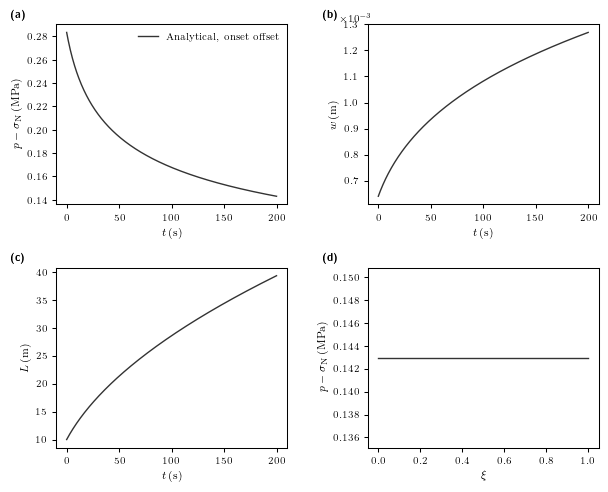

In [13]:
t_target = t_end
t_idx_ana = int(np.argmin(np.abs(t_sim - t_target)))
ss_kw = dict(color="#333333", linestyle="-.", linewidth=1.0)

# 2x2 figure (Science double-column: 7 in wide)
fig, axes = plt.subplots(
    2, 2, figsize=(7, 5.5), gridspec_kw={"hspace": 0.35, "wspace": 0.35}
)

for ax in axes.flat:
    for spine in ax.spines.values():
        spine.set_linewidth(0.75)
    ax.tick_params(direction="out", length=3, width=0.75, labelsize=7)

num_kw = dict(
    linestyle="--",
    color="#c0392b",
    linewidth=1.0,
    marker="D",
    markersize=3.2,
    markerfacecolor="none",
    markeredgewidth=0.75,
)

# Panel (a): net pressure at the injection point
ax0 = axes[0, 0]
ax0.plot(
    tCenter,
    np.array(pressureCenter) / 1e6,
    color="#333333",
    linestyle="-",
    linewidth=1.0,
    label=r"$\mathrm{Analytical,\ onset\ offset}$",
)
ax0.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax0.set_ylabel(r"$p-\sigma_{\mathrm{N}}\,\mathrm{(MPa)}$", fontsize=8)
ax0.set_ylabel(r"$p-\sigma_{\mathrm{N}}\,\mathrm{(MPa)}$", fontsize=8)
ax0.legend(fontsize=7, frameon=False)
ax0.text(-0.2, 1.02, r"\textbf{(a)}", transform=ax0.transAxes, fontsize=8, va="bottom")

# Panel (b): fracture aperture at the injection point
ax1 = axes[0, 1]
ax1.plot(tCenter, openingCenter, color="#333333", linestyle="-", linewidth=1.0)
ax1.ticklabel_format(style="sci", scilimits=(-1, 2), axis="y")
off = ax1.yaxis.get_offset_text()
off.set_fontsize(7)
off.set_x(-0.12)
ax1.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax1.set_ylabel(r"$w\,\mathrm{(m)}$", fontsize=8)
ax1.text(-0.2, 1.02, r"\textbf{(b)}", transform=ax1.transAxes, fontsize=8, va="bottom")

# Panel (c): fracture half-length
ax2 = axes[1, 0]
ax2.plot(tCenter, length, color="#333333", linestyle="-", linewidth=1.0)
ax2.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax2.set_ylabel(r"$L\,\mathrm{(m)}$", fontsize=8)
ax2.text(-0.2, 1.02, r"\textbf{(c)}", transform=ax2.transAxes, fontsize=8, va="bottom")

# Panel (d): net pressure profile along the fracture at t_target
ax3 = axes[1, 1]
ax3.plot(
    xi, pressure[:, t_idx_ana] / 1e6, color="#333333", linestyle="-", linewidth=1.0
)
ax3.set_xlabel(r"$\xi$", fontsize=8)
ax3.set_ylabel(r"$p-\sigma_{\mathrm{N}}\,\mathrm{(MPa)}$", fontsize=8)
ax3.text(-0.2, 1.02, r"\textbf{(d)}", transform=ax3.transAxes, fontsize=8, va="bottom")

# plt.savefig("KGD_toughness_leakoff_results.pdf", bbox_inches="tight", dpi=600)

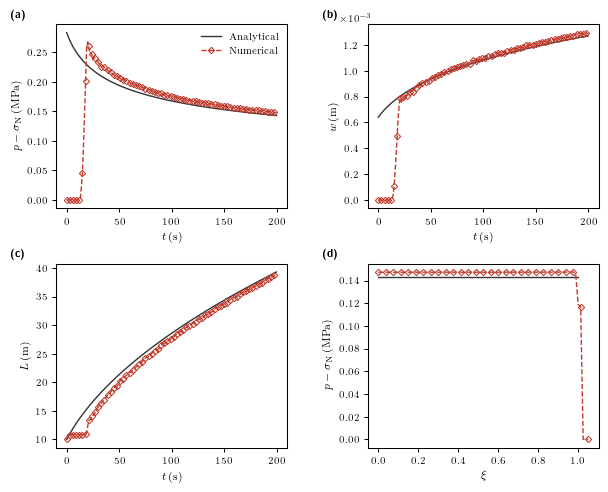

In [ ]:
# Build the 2x2 figure from the exported CSVs from the phase-field simulation; the
# analytical curves are the ones computed above (simulation time, onset offset t0).
import matplotlib.pyplot as plt
import numpy as np

_rd = lambda f: np.genfromtxt(f, delimiter=",", names=True)
num_ts = _rd("../../data/K_bar_vertex/numerical_timeseries.csv")
num_pr = _rd("../../data/K_bar_vertex/numerical_profile_t200.csv")

# the masks the figure above applies (t <= 200 s, xi <= 1.05)
m_t = (num_ts["t_s"] >= 0) & (num_ts["t_s"] <= t_end)
m_x = (num_pr["xi"] >= 0) & (num_pr["xi"] <= 1.05)
# analytical profile at the time of the numerical one
t_idx_pr = int(np.argmin(np.abs(t_sim - num_pr["t_s"][0])))

# panel tags fall back to plain text where LaTeX is not configured
_tag = (
    (lambda s: rf"\textbf{{({s})}}")
    if plt.rcParams["text.usetex"]
    else (lambda s: f"({s})")
)
ANA = dict(color="#333333", linestyle="-", linewidth=1.0)
NUM = dict(
    linestyle="--",
    color="#c0392b",
    linewidth=1.0,
    marker="D",
    markersize=3.2,
    markerfacecolor="none",
    markeredgewidth=0.75,
    markevery=3,
)

fig, axes = plt.subplots(
    2, 2, figsize=(7, 5.5), gridspec_kw={"hspace": 0.3, "wspace": 0.35}
)
for ax in axes.flat:
    for spine in ax.spines.values():
        spine.set_linewidth(0.75)
    ax.tick_params(direction="out", length=3, width=0.75, labelsize=7)

# (a) pressure vs time
ax0 = axes[0, 0]
ax0.plot(
    tCenter,
    np.array(pressureCenter) / 1e6,
    label=r"$\mathrm{Analytical}$",
    **ANA,
)
ax0.plot(
    num_ts["t_s"][m_t],
    num_ts["p_net_Pa"][m_t] / 1e6,
    label=r"$\mathrm{Numerical}$",
    **NUM,
)
ax0.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax0.set_ylabel(r"$p-\sigma_{\mathrm{N}}\,\mathrm{(MPa)}$", fontsize=8)
ax0.legend(fontsize=7, frameon=False, loc="upper right")
ax0.text(-0.2, 1.02, _tag("a"), transform=ax0.transAxes, fontsize=8, va="bottom")

# (b) opening vs time
ax1 = axes[0, 1]
ax1.plot(tCenter, openingCenter, **ANA)
ax1.plot(num_ts["t_s"][m_t], num_ts["w_m"][m_t], **NUM)
ax1.ticklabel_format(style="sci", scilimits=(-1, 2), axis="y")
ot = ax1.yaxis.get_offset_text()
ot.set_fontsize(7)
ot.set_x(-0.12)
ax1.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax1.set_ylabel(r"$w\,\mathrm{(m)}$", fontsize=8)
ax1.text(-0.2, 1.02, _tag("b"), transform=ax1.transAxes, fontsize=8, va="bottom")

# (c) crack length vs time
ax2 = axes[1, 0]
ax2.plot(tCenter, length, **ANA)
ax2.plot(num_ts["t_s"][m_t], num_ts["L_m"][m_t], **NUM)
ax2.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax2.set_ylabel(r"$L\,\mathrm{(m)}$", fontsize=8)
ax2.text(-0.2, 1.02, _tag("c"), transform=ax2.transAxes, fontsize=8, va="bottom")

# (d) pressure profile at t = 200 s
ax3 = axes[1, 1]
ax3.plot(xi, pressure[:, t_idx_pr] / 1e6, **ANA)
ax3.plot(num_pr["xi"][m_x], num_pr["p_net_Pa"][m_x] / 1e6, **NUM)
ax3.set_xlabel(r"$\xi$", fontsize=8)
ax3.set_ylabel(r"$p-\sigma_\mathrm{N}\,\mathrm{(MPa)}$", fontsize=8)
ax3.text(-0.2, 1.02, _tag("d"), transform=ax3.transAxes, fontsize=8, va="bottom")

plt.savefig(
    "../../figures/KGD_leakoff_toughness_results.pdf", bbox_inches="tight", dpi=300
)
plt.show()